# TP — Knowledge Distillation

Je compare ResNet50, ResNet18 et mes propres CNN sur CIFAR-10. Je mesure la précision et l’efficacité, puis je compare plusieurs méthodes de distillation. Le notebook sauvegarde les résultats après chaque expérience.

## 0. Préparation
Sur Kaggle, j’active **GPU** et **Internet**. Je lance ensuite toutes les cellules dans l’ordre, **une seule fois**. Les résultats sont enregistrés dans `/kaggle/working/kd_final/`. Si je redémarre le notebook avec les fichiers de sortie encore présents, le code peut reprendre les expériences non terminées.

In [1]:
%pip -q install thop scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os, io, time, json, random, copy, gc, zipfile
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader, Subset
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report
from thop import profile
from IPython.display import display

SEED = 42
IMAGE_SIZE = 128
BATCH_SIZE = 64
EPOCHS = 2  # Je garde 2 pour le dernier essai rapide; augmenter seulement si possible
LR = 1e-4
TEMPERATURE = 4.0
ALPHA = 0.5
BETA_FEATURE = 1.0
NUM_WORKERS = 2
RUN_CUSTOM = True
RUN_DISTANCES = True
RUN_CONFUSIONS = True

OUT = Path('/kaggle/working/kd_final') if Path('/kaggle/working').exists() else Path('kd_final')
OUT.mkdir(parents=True, exist_ok=True)
CKPT = OUT / 'checkpoints'; CKPT.mkdir(exist_ok=True)
FIG = OUT / 'figures'; FIG.mkdir(exist_ok=True)
HIST = OUT / 'histories'; HIST.mkdir(exist_ok=True)
RESULTS_FILE = OUT / 'results.csv'
CONFIG_FILE = OUT / 'configuration.json'

config = dict(seed=SEED, image_size=IMAGE_SIZE, batch_size=BATCH_SIZE, epochs=EPOCHS,
              lr=LR, temperature=TEMPERATURE, alpha=ALPHA, beta_feature=BETA_FEATURE)
if CONFIG_FILE.exists():
    old = json.loads(CONFIG_FILE.read_text())
    if old != config:
        raise RuntimeError('Réglages différents des anciens résultats : choisir un autre dossier OUT ou remettre les anciens réglages.')
else:
    CONFIG_FILE.write_text(json.dumps(config, indent=2))

def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
set_seed()
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
if device.type != 'cuda':
    raise RuntimeError('GPU non activé. Activer un accélérateur GPU dans Kaggle avant de continuer.')
torch.backends.cudnn.benchmark = True
print('GPU :', torch.cuda.get_device_name(0))
print('Fichiers :', OUT.resolve())

GPU : Tesla T4
Fichiers : /kaggle/working/kd_final


## 1. CIFAR-10
Je prends 45 000 images pour l’entraînement, 5 000 pour la validation et 10 000 pour le test. Je garde les mêmes images et la même taille pour tous les modèles.

In [3]:
mean = (0.485, 0.456, 0.406)
std = (0.229, 0.224, 0.225)
train_tf = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(), transforms.Normalize(mean, std)])
eval_tf = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(), transforms.Normalize(mean, std)])
base_train = datasets.CIFAR10('./data', train=True, download=True, transform=train_tf)
base_val = datasets.CIFAR10('./data', train=True, download=False, transform=eval_tf)
test_ds = datasets.CIFAR10('./data', train=False, download=True, transform=eval_tf)
order = torch.randperm(len(base_train), generator=torch.Generator().manual_seed(SEED)).tolist()
train_ds = Subset(base_train, order[:45000])
val_ds = Subset(base_val, order[45000:])
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS, pin_memory=True)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True)
CLASSES = test_ds.classes
print('Train',len(train_ds),'Val',len(val_ds),'Test',len(test_ds))

100%|██████████| 170M/170M [57:55<00:00, 49.1kB/s]   


Train 45000 Val 5000 Test 10000


## 2. Modèles et fonctions
Le professeur ResNet50 est pré-entraîné sur ImageNet. Je compare ensuite deux types de ResNet18 : avec et sans pré-entraînement. Pour les *feature maps*, j’utilise une convolution 1×1 quand les canaux sont différents.

In [4]:
def make_resnet(kind, pretrained):
    if kind == 'resnet50':
        weights = models.ResNet50_Weights.DEFAULT if pretrained else None
        net = models.resnet50(weights=weights)
    else:
        weights = models.ResNet18_Weights.DEFAULT if pretrained else None
        net = models.resnet18(weights=weights)
    net.fc = nn.Linear(net.fc.in_features, 10)
    return net.to(device)

class SmallCNN(nn.Module):
    def __init__(self, width=64):
        super().__init__()
        w = width
        self.features = nn.Sequential(
            nn.Conv2d(3,w,3,padding=1), nn.BatchNorm2d(w), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(w,2*w,3,padding=1), nn.BatchNorm2d(2*w), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(2*w,4*w,3,padding=1), nn.BatchNorm2d(4*w), nn.ReLU(), nn.MaxPool2d(2))
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Linear(4*w,10)
        self.feature_channels = 4*w
    def forward(self,x):
        z = self.features(x)
        return self.fc(self.pool(z).flatten(1))

def target_layer(net):
    return net.layer3 if hasattr(net,'layer3') else net.features

def channels(net):
    if hasattr(net,'layer3'):
        return 1024 if isinstance(net.layer3[0],models.resnet.Bottleneck) else 256
    return net.feature_channels

class Capture:
    def __init__(self,net):
        self.value = None
        self.handle = target_layer(net).register_forward_hook(self.hook)
    def hook(self,module,inputs,output): self.value = output
    def close(self): self.handle.remove()

@torch.no_grad()
def evaluate(net,loader):
    net.eval()
    total=correct=0; total_loss=0.
    for x,y in loader:
        x=x.to(device,non_blocking=True); y=y.to(device,non_blocking=True)
        logits=net(x)
        total_loss += F.cross_entropy(logits,y,reduction='sum').item()
        correct += (logits.argmax(1)==y).sum().item()
        total += len(y)
    return {'loss':total_loss/total,'accuracy':100*correct/total}

def kd_distance(s,t,metric):
    if metric=='mse': return F.mse_loss(s,t)
    if metric=='cosine': return (1-F.cosine_similarity(s,t,dim=1)).mean()
    if metric=='kld':
        return F.kl_div(F.log_softmax(s/TEMPERATURE,dim=1),
                        F.softmax(t/TEMPERATURE,dim=1),reduction='batchmean')*TEMPERATURE**2
    raise ValueError(metric)

def key_for(name):
    return ''.join(ch if ch.isalnum() else '_' for ch in name).strip('_').lower()

def load_results():
    return pd.read_csv(RESULTS_FILE) if RESULTS_FILE.exists() else pd.DataFrame()

def add_result(row):
    table=load_results()
    table=table[table['Model']!=row['Model']] if not table.empty else table
    table=pd.concat([table,pd.DataFrame([row])],ignore_index=True)
    table.to_csv(RESULTS_FILE,index=False)
    return table

def save_progress(path, epoch, model, adapter, optimizer, history, best_acc, best_state, seconds):
    tmp=path.with_suffix('.tmp')
    torch.save(dict(epoch=epoch, model=model.state_dict(),
                    adapter=adapter.state_dict() if adapter is not None else None,
                    optimizer=optimizer.state_dict(),history=history,
                    best_acc=best_acc,best_state=best_state,seconds=seconds),tmp)
    os.replace(tmp,path)

## 3. Entraîner et mesurer
Après chaque époque, je sauvegarde un point de reprise et la courbe de validation. Si une expérience est déjà terminée, je recharge ses poids sans la refaire. Je mesure ensuite les six métriques d’efficacité du cours.

In [5]:
def train_one(net, name, teacher=None, metric='kld', use_features=False):
    net=net.to(device)
    progress_path=CKPT/(key_for(name)+'_progress.pt')
    best_path=CKPT/(key_for(name)+'_best.pt')
    optimizer_params=list(net.parameters())
    adapter=None; thook=shook=None
    if teacher is not None:
        teacher.eval()
        for p in teacher.parameters(): p.requires_grad_(False)
        if use_features:
            thook=Capture(teacher); shook=Capture(net)
            adapter=nn.Conv2d(channels(net),channels(teacher),1).to(device)
            optimizer_params += list(adapter.parameters())
    opt=torch.optim.Adam(optimizer_params,lr=LR)
    history=[]; best_acc=-1.; best_state=None
    start_epoch=0; previous_seconds=0.
    if progress_path.exists():
        state=torch.load(progress_path,map_location=device,weights_only=False)
        net.load_state_dict(state['model'])
        if adapter is not None and state['adapter'] is not None:adapter.load_state_dict(state['adapter'])
        opt.load_state_dict(state['optimizer'])
        history=state['history'];best_acc=state['best_acc'];best_state=state['best_state']
        start_epoch=state['epoch'];previous_seconds=state['seconds']
        print(name, ': reprise à l’époque',start_epoch+1)
    try:
        for epoch in range(start_epoch,EPOCHS):
            net.train();running=0.;seen=0
            if device.type=='cuda':torch.cuda.synchronize()
            st=time.perf_counter()
            for x,y in train_loader:
                x=x.to(device,non_blocking=True);y=y.to(device,non_blocking=True)
                opt.zero_grad(set_to_none=True)
                scores=net(x)
                ce=F.cross_entropy(scores,y)
                if teacher is None:
                    loss=ce
                else:
                    with torch.no_grad(): t_scores=teacher(x)
                    loss=ALPHA*ce+(1-ALPHA)*kd_distance(scores,t_scores,metric)
                    if use_features:
                        sf=adapter(shook.value)
                        tf=thook.value.detach()
                        if sf.shape[-2:]!=tf.shape[-2:]:
                            sf=F.adaptive_avg_pool2d(sf,tf.shape[-2:])
                        loss=loss+BETA_FEATURE*F.mse_loss(sf,tf)
                loss.backward();opt.step()
                running+=loss.item()*len(y);seen+=len(y)
            if device.type=='cuda':torch.cuda.synchronize()
            previous_seconds+=time.perf_counter()-st
            val=evaluate(net,val_loader)
            history.append(dict(epoch=epoch+1,train_loss=running/seen,
                                val_loss=val['loss'],val_accuracy=val['accuracy']))
            if val['accuracy']>best_acc:
                best_acc=val['accuracy']
                best_state=copy.deepcopy({k:v.detach().cpu() for k,v in net.state_dict().items()})
                torch.save(best_state,best_path)
            pd.DataFrame(history).to_csv(HIST/(key_for(name)+'.csv'),index=False)
            save_progress(progress_path,epoch+1,net,adapter,opt,history,best_acc,best_state,previous_seconds)
            print(f'{name} — époque {epoch+1}/{EPOCHS} — perte {running/seen:.3f} — validation {val["accuracy"]:.2f}%')
    finally:
        if thook is not None:thook.close()
        if shook is not None:shook.close()
    net.load_state_dict(torch.load(best_path,map_location=device,weights_only=True))
    return net,previous_seconds,best_acc

def benchmark(net,name,train_seconds,best_val):
    net.eval().to(device)
    count=sum(p.numel() for p in net.parameters())
    stream=io.BytesIO();torch.save(net.state_dict(),stream)
    size_mb=stream.tell()/1024**2;stream.close()
    dummy=torch.randn(1,3,IMAGE_SIZE,IMAGE_SIZE,device=device)
    with torch.inference_mode():
        macs,_=profile(net,inputs=(dummy,),verbose=False)
        for _ in range(5):net(dummy)
    torch.cuda.synchronize()
    t0=time.perf_counter();total=correct=0; ce_sum=0.
    with torch.inference_mode():
        for x,y in test_loader:
            logits=net(x.to(device,non_blocking=True))
            correct+=(logits.argmax(1).cpu()==y).sum().item()
            ce_sum+=F.cross_entropy(logits,y.to(device),reduction='sum').item()
            total+=len(y)
    torch.cuda.synchronize()
    seconds=time.perf_counter()-t0
    row={'Model':name,'Test accuracy (%)':100*correct/total,'Test CE loss':ce_sum/total,
         'Best val accuracy (%)':best_val,'Parameters (M)':count/1e6,
         'Model size (MB)':size_mb,'Training time (min)':train_seconds/60,
         'Inference time (ms/image)':seconds*1000/total,
         'Throughput (FPS)':total/seconds,'GFLOPs (approx)':2*macs/1e9}
    add_result(row)
    display(pd.DataFrame([row]).round(3))
    return row

def run_experiment(name,factory,teacher=None,metric='kld',features=False):
    best_path=CKPT/(key_for(name)+'_best.pt')
    table=load_results()
    net=factory()
    completed=not table.empty and name in table['Model'].values and best_path.exists()
    if completed:
        print('Déjà terminé :',name)
        net.load_state_dict(torch.load(best_path,map_location=device,weights_only=True))
        return net
    net,secs,best=train_one(net,name,teacher,metric,features)
    benchmark(net,name,secs,best)
    return net

## 4. ResNet50 et ResNet18
Je commence avec le professeur, puis je teste les deux stratégies. Je repars des mêmes poids de départ pour chaque méthode.

In [6]:
teacher=run_experiment('ResNet50 teacher',lambda:make_resnet('resnet50',True))
student_pretrained=run_experiment('ResNet18 pretrained baseline',lambda:make_resnet('resnet18',True))
student_pretrained_scores=run_experiment('ResNet18 pretrained scores KD',lambda:make_resnet('resnet18',True),teacher=teacher)
student_pretrained_features=run_experiment('ResNet18 pretrained scores+features KD',lambda:make_resnet('resnet18',True),teacher=teacher,features=True)
student_scratch=run_experiment('ResNet18 scratch baseline',lambda:make_resnet('resnet18',False))
student_scratch_scores=run_experiment('ResNet18 scratch scores KD',lambda:make_resnet('resnet18',False),teacher=teacher)
student_scratch_features=run_experiment('ResNet18 scratch scores+features KD',lambda:make_resnet('resnet18',False),teacher=teacher,features=True)

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 222MB/s]


ResNet50 teacher — époque 1/2 — perte 0.312 — validation 95.96%
ResNet50 teacher — époque 2/2 — perte 0.095 — validation 95.58%


,Model,Test accuracy (%),Test CE loss,Best val accuracy (%),Parameters (M),Model size (MB),Training time (min),Inference time (ms/image),Throughput (FPS),GFLOPs (approx)
0,ResNet50 teacher,95.48,0.138,95.96,23.529,90.057,5.033,1.074,931.096,2.698


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 213MB/s]


... (8 outputs left out)

ResNet18 scratch scores KD — époque 1/2 — perte 2.830 — validation 63.38%
ResNet18 scratch scores KD — époque 2/2 — perte 1.801 — validation 68.02%


,Model,Test accuracy (%),Test CE loss,Best val accuracy (%),Parameters (M),Model size (MB),Training time (min),Inference time (ms/image),Throughput (FPS),GFLOPs (approx)
0,ResNet18 scratch scores KD,68.76,1.066,68.02,11.182,42.73,3.054,0.476,2099.433,1.191


ResNet18 scratch scores+features KD — époque 1/2 — perte 4.060 — validation 61.80%
ResNet18 scratch scores+features KD — époque 2/2 — perte 2.861 — validation 71.74%


,Model,Test accuracy (%),Test CE loss,Best val accuracy (%),Parameters (M),Model size (MB),Training time (min),Inference time (ms/image),Throughput (FPS),GFLOPs (approx)
0,ResNet18 scratch scores+features KD,71.49,0.898,71.74,11.182,42.73,3.128,0.486,2058.898,1.191


## 5. Comparer les distances
Je compare KL divergence, MSE et distance cosinus pour les scores. Le modèle et les données sont les mêmes.

In [7]:
if RUN_DISTANCES:
    student_mse=run_experiment('ResNet18 pretrained scores KD mse',lambda:make_resnet('resnet18',True),teacher=teacher,metric='mse')
    student_cosine=run_experiment('ResNet18 pretrained scores KD cosine',lambda:make_resnet('resnet18',True),teacher=teacher,metric='cosine')

ResNet18 pretrained scores KD mse — époque 1/2 — perte 0.836 — validation 93.40%
ResNet18 pretrained scores KD mse — époque 2/2 — perte 0.411 — validation 94.58%


,Model,Test accuracy (%),Test CE loss,Best val accuracy (%),Parameters (M),Model size (MB),Training time (min),Inference time (ms/image),Throughput (FPS),GFLOPs (approx)
0,ResNet18 pretrained scores KD mse,94.12,0.175,94.58,11.182,42.73,3.044,0.491,2038.615,1.191


ResNet18 pretrained scores KD cosine — époque 1/2 — perte 0.205 — validation 93.38%
ResNet18 pretrained scores KD cosine — époque 2/2 — perte 0.093 — validation 93.92%


,Model,Test accuracy (%),Test CE loss,Best val accuracy (%),Parameters (M),Model size (MB),Training time (min),Inference time (ms/image),Throughput (FPS),GFLOPs (approx)
0,ResNet18 pretrained scores KD cosine,93.67,0.191,93.92,11.182,42.73,3.055,0.484,2067.176,1.191


## 6. Mes propres CNN
Je crée un professeur de largeur 64, puis des étudiants de largeur 32, 21 et 16. Je teste chaque étudiant sans distillation, avec les scores, puis avec les scores et les *feature maps*. Ces nombres divisent la largeur du réseau, pas exactement le nombre total de paramètres.

In [8]:
if RUN_CUSTOM:
    custom_teacher=run_experiment('Custom teacher w64',lambda:SmallCNN(64).to(device))
    for factor in (2,3,4):
        w=64//factor
        _=run_experiment(f'Custom student x{factor} baseline',lambda w=w:SmallCNN(w).to(device))
        _=run_experiment(f'Custom student x{factor} scores KD',lambda w=w:SmallCNN(w).to(device),teacher=custom_teacher)
        _=run_experiment(f'Custom student x{factor} scores+features KD',lambda w=w:SmallCNN(w).to(device),teacher=custom_teacher,features=True)
    del custom_teacher
    gc.collect();torch.cuda.empty_cache()

Custom teacher w64 — époque 1/2 — perte 1.749 — validation 43.12%
Custom teacher w64 — époque 2/2 — perte 1.524 — validation 48.84%


,Model,Test accuracy (%),Test CE loss,Best val accuracy (%),Parameters (M),Model size (MB),Training time (min),Inference time (ms/image),Throughput (FPS),GFLOPs (approx)
0,Custom teacher w64,48.03,1.473,48.84,0.374,1.438,2.087,0.559,1787.868,1.279


Custom student x2 baseline — époque 1/2 — perte 1.885 — validation 38.62%
Custom student x2 baseline — époque 2/2 — perte 1.683 — validation 43.08%


,Model,Test accuracy (%),Test CE loss,Best val accuracy (%),Parameters (M),Model size (MB),Training time (min),Inference time (ms/image),Throughput (FPS),GFLOPs (approx)
0,Custom student x2 baseline,42.97,1.619,43.08,0.095,0.371,1.007,0.47,2125.816,0.338


Custom student x2 scores KD — époque 1/2 — perte 1.077 — validation 39.84%
Custom student x2 scores KD — époque 2/2 — perte 0.877 — validation 43.76%


,Model,Test accuracy (%),Test CE loss,Best val accuracy (%),Parameters (M),Model size (MB),Training time (min),Inference time (ms/image),Throughput (FPS),GFLOPs (approx)
0,Custom student x2 scores KD,43.47,1.591,43.76,0.095,0.371,1.656,0.458,2183.742,0.338


... (10 outputs left out)

Custom student x4 scores KD — époque 1/2 — perte 1.210 — validation 33.78%
Custom student x4 scores KD — époque 2/2 — perte 0.974 — validation 39.98%


,Model,Test accuracy (%),Test CE loss,Best val accuracy (%),Parameters (M),Model size (MB),Training time (min),Inference time (ms/image),Throughput (FPS),GFLOPs (approx)
0,Custom student x4 scores KD,39.81,1.687,39.98,0.024,0.101,1.221,0.457,2186.326,0.093


Custom student x4 scores+features KD — époque 1/2 — perte 1.964 — validation 33.46%
Custom student x4 scores+features KD — époque 2/2 — perte 1.351 — validation 37.80%


,Model,Test accuracy (%),Test CE loss,Best val accuracy (%),Parameters (M),Model size (MB),Training time (min),Inference time (ms/image),Throughput (FPS),GFLOPs (approx)
0,Custom student x4 scores+features KD,38.09,1.691,37.8,0.024,0.101,1.26,0.464,2156.395,0.093


## 7. Tableau final
Je relis les résultats sauvegardés. Ainsi, je garde aussi les premières expériences. Une ligne correspond à un seul modèle et une seule méthode.

In [9]:
comparison=load_results().drop_duplicates(subset='Model',keep='last').copy()
expected=['ResNet50 teacher','ResNet18 pretrained baseline',
'ResNet18 pretrained scores KD','ResNet18 pretrained scores+features KD',
'ResNet18 scratch baseline','ResNet18 scratch scores KD',
'ResNet18 scratch scores+features KD']
if RUN_DISTANCES:
    expected += ['ResNet18 pretrained scores KD mse','ResNet18 pretrained scores KD cosine']
if RUN_CUSTOM:
    expected += ['Custom teacher w64'] + [f'Custom student x{k} {mode}' for k in (2,3,4) for mode in ('baseline','scores KD','scores+features KD')]
missing=[x for x in expected if x not in comparison['Model'].tolist()]
if missing:print('Expériences manquantes :',missing)
else: print('Toutes les expériences sont présentes :',len(expected))
comparison['order']=comparison['Model'].map({x:i for i,x in enumerate(expected)})
comparison=comparison.sort_values('order').drop(columns='order')
base=comparison.loc[comparison['Model']=='ResNet50 teacher']
if not base.empty:
    comparison['Parameter reduction vs ResNet50 (%)']=100*(1-comparison['Parameters (M)']/base.iloc[0]['Parameters (M)'])
    comparison['FLOPs reduction vs ResNet50 (%)']=100*(1-comparison['GFLOPs (approx)']/base.iloc[0]['GFLOPs (approx)'])
comparison.to_csv(OUT/'comparaison_complete.csv',index=False)
display(comparison.round(3))

Toutes les expériences sont présentes : 19


,Model,Test accuracy (%),Test CE loss,Best val accuracy (%),Parameters (M),Model size (MB),Training time (min),Inference time (ms/image),Throughput (FPS),GFLOPs (approx),Parameter reduction vs ResNet50 (%),FLOPs reduction vs ResNet50 (%)
0,ResNet50 teacher,95.48,0.138,95.96,23.529,90.057,5.033,1.074,931.096,2.698,0.000,0.000
1,ResNet18 pretrained baseline,92.98,0.214,93.30,11.182,42.730,1.554,0.496,2015.941,1.191,52.476,55.865
2,ResNet18 pretrained scores KD,94.41,0.165,94.90,11.182,42.730,3.048,0.492,2031.361,1.191,52.476,55.865
3,ResNet18 pretrained scores+features KD,93.98,0.179,94.40,11.182,42.730,3.122,0.474,2109.585,1.191,52.476,55.865
4,ResNet18 scratch baseline,70.02,0.847,70.32,11.182,42.730,1.542,0.495,2018.756,1.191,52.476,55.865
5,ResNet18 scratch scores KD,68.76,1.066,68.02,11.182,42.730,3.054,0.476,2099.433,1.191,52.476,55.865
6,ResNet18 scratch scores+features KD,71.49,0.898,71.74,11.182,42.730,3.128,0.486,2058.898,1.191,52.476,55.865
7,ResNet18 pretrained scores KD mse,94.12,0.175,94.58,11.182,42.730,3.044,0.491,2038.615,1.191,52.476,55.865
8,ResNet18 pretrained scores KD cosine,93.67,0.191,93.92,11.182,42.730,3.055,0.484,2067.176,1.191,52.476,55.865
9,Custom teacher w64,48.03,1.473,48.84,0.374,1.438,2.087,0.559,1787.868,1.279,98.409,52.585


## 8. Graphiques
Je regarde l’évolution pendant les époques, puis je compare la précision avec la taille, le coût et la vitesse des modèles. Les figures sont enregistrées pour le rapport.

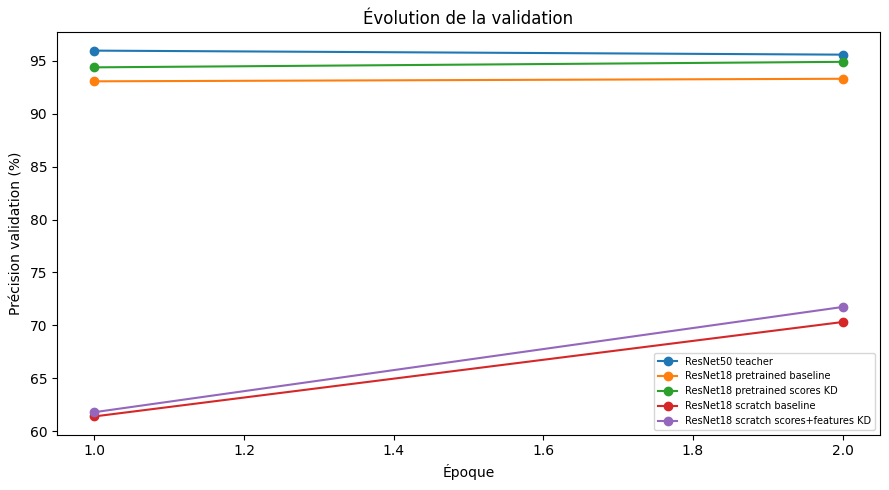

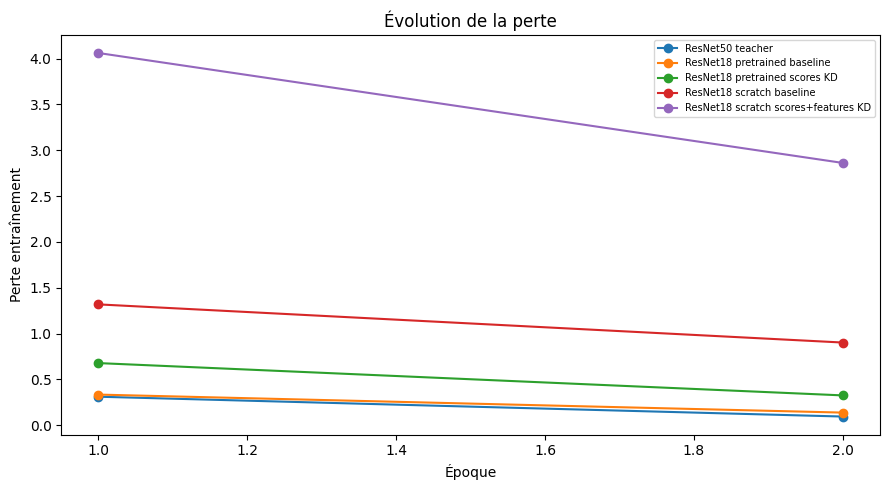

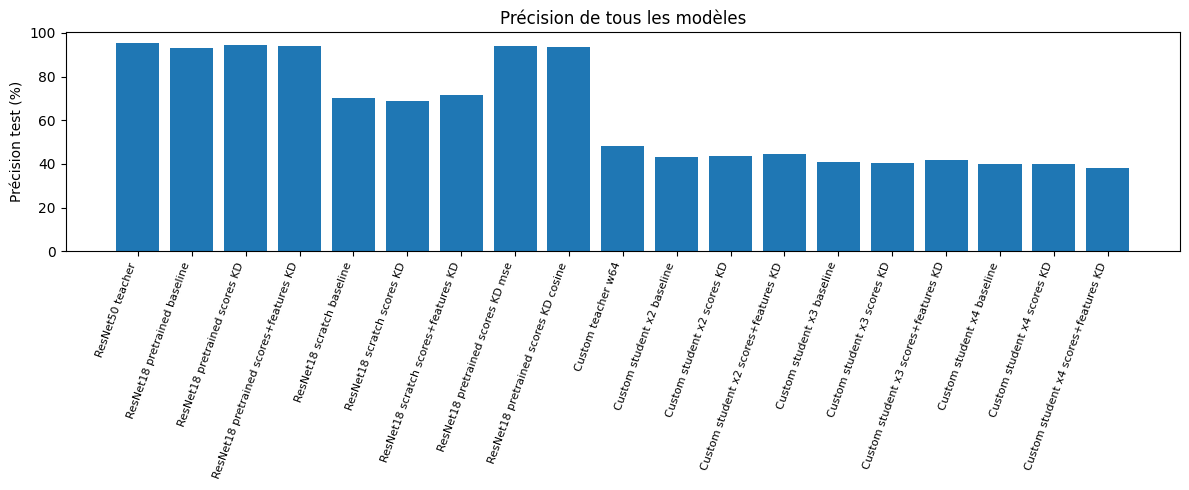

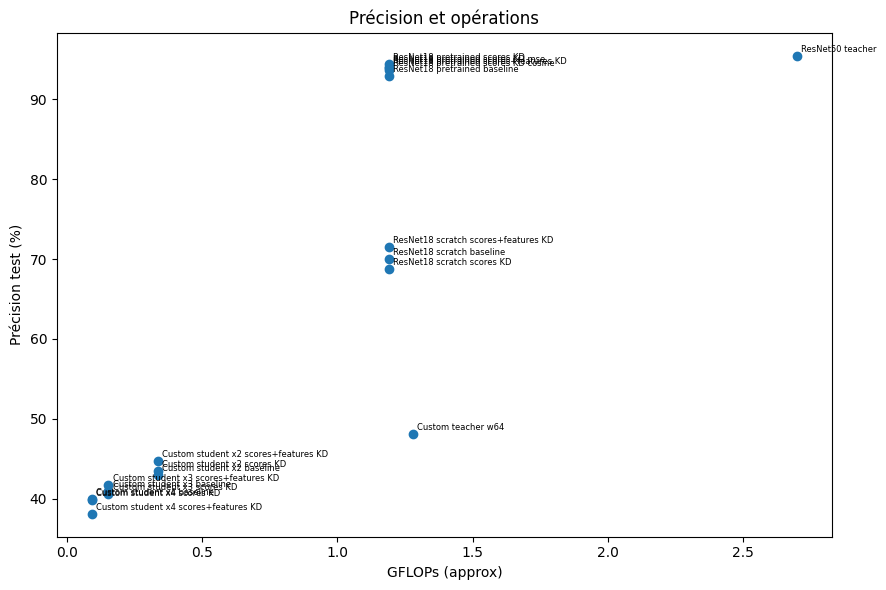

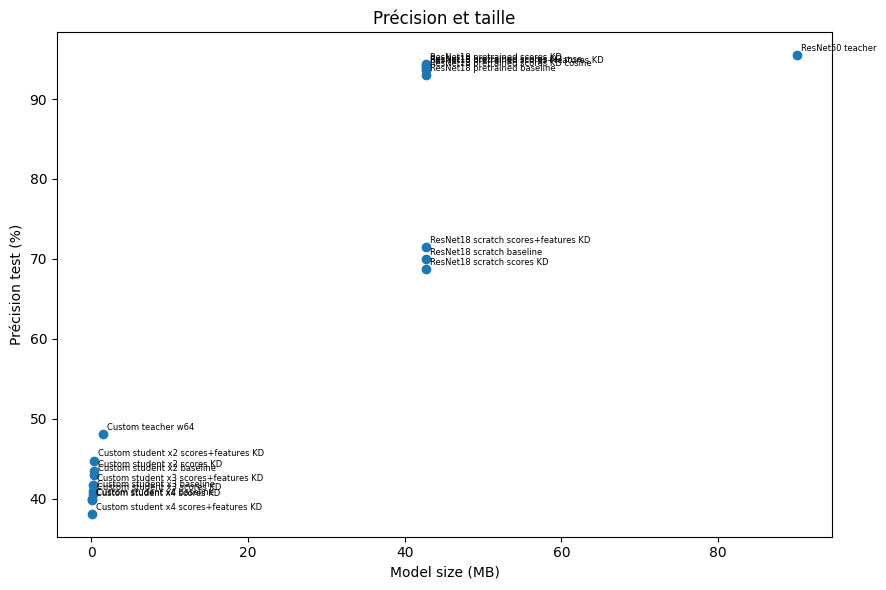

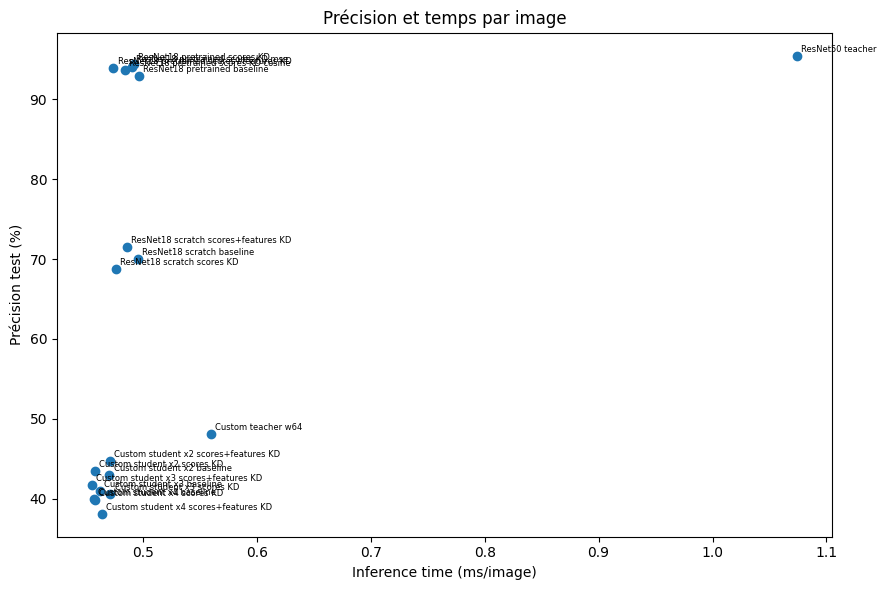

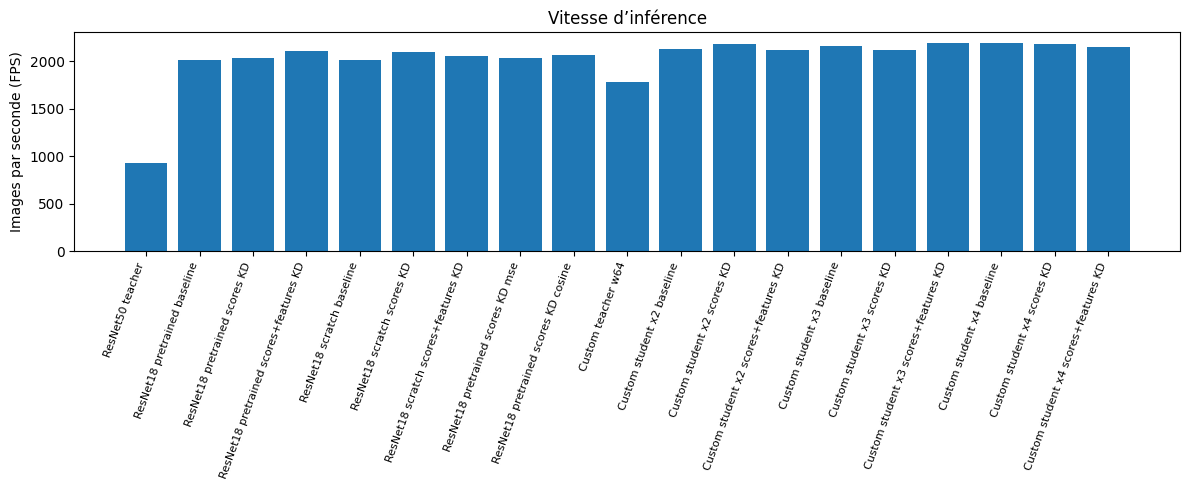

In [10]:
def save_show(name):
    plt.tight_layout()
    plt.savefig(FIG/name,dpi=170,bbox_inches='tight')
    plt.show()

# Courbes : validation et perte d'entraînement
selected=['ResNet50 teacher','ResNet18 pretrained baseline',
          'ResNet18 pretrained scores KD','ResNet18 scratch baseline',
          'ResNet18 scratch scores+features KD']
fig,ax=plt.subplots(figsize=(9,5))
for name in selected:
    p=HIST/(key_for(name)+'.csv')
    if p.exists():
        h=pd.read_csv(p);ax.plot(h['epoch'],h['val_accuracy'],marker='o',label=name)
ax.set(xlabel='Époque',ylabel='Précision validation (%)',title='Évolution de la validation')
ax.legend(fontsize=7)
save_show('01_validation.png')

fig,ax=plt.subplots(figsize=(9,5))
for name in selected:
    p=HIST/(key_for(name)+'.csv')
    if p.exists():
        h=pd.read_csv(p);ax.plot(h['epoch'],h['train_loss'],marker='o',label=name)
ax.set(xlabel='Époque',ylabel='Perte entraînement',title='Évolution de la perte')
ax.legend(fontsize=7)
save_show('02_train_loss.png')

fig,ax=plt.subplots(figsize=(12,5))
ax.bar(comparison['Model'],comparison['Test accuracy (%)'])
ax.set(ylabel='Précision test (%)',title='Précision de tous les modèles')
plt.xticks(rotation=70,ha='right',fontsize=8)
save_show('03_accuracy.png')

for xcol,filename,title in [
    ('GFLOPs (approx)','04_accuracy_flops.png','Précision et opérations'),
    ('Model size (MB)','05_accuracy_size.png','Précision et taille'),
    ('Inference time (ms/image)','06_accuracy_latency.png','Précision et temps par image')]:
    fig,ax=plt.subplots(figsize=(9,6))
    ax.scatter(comparison[xcol],comparison['Test accuracy (%)'])
    for _,r in comparison.iterrows():
        ax.annotate(r['Model'],(r[xcol],r['Test accuracy (%)']),fontsize=6,xytext=(3,3),textcoords='offset points')
    ax.set(xlabel=xcol,ylabel='Précision test (%)',title=title)
    save_show(filename)

fig,ax=plt.subplots(figsize=(12,5))
ax.bar(comparison['Model'],comparison['Throughput (FPS)'])
ax.set(ylabel='Images par seconde (FPS)',title='Vitesse d’inférence')
plt.xticks(rotation=70,ha='right',fontsize=8)
save_show('07_fps.png')

## 9. Matrices de confusion
Je regarde aussi les erreurs de classification pour le professeur, le meilleur ResNet18 pré-entraîné selon la validation, et un étudiant sans pré-entraînement. Je choisis le meilleur étudiant avec la validation et non avec le test.

Modèle choisi par validation : ResNet18 pretrained scores KD


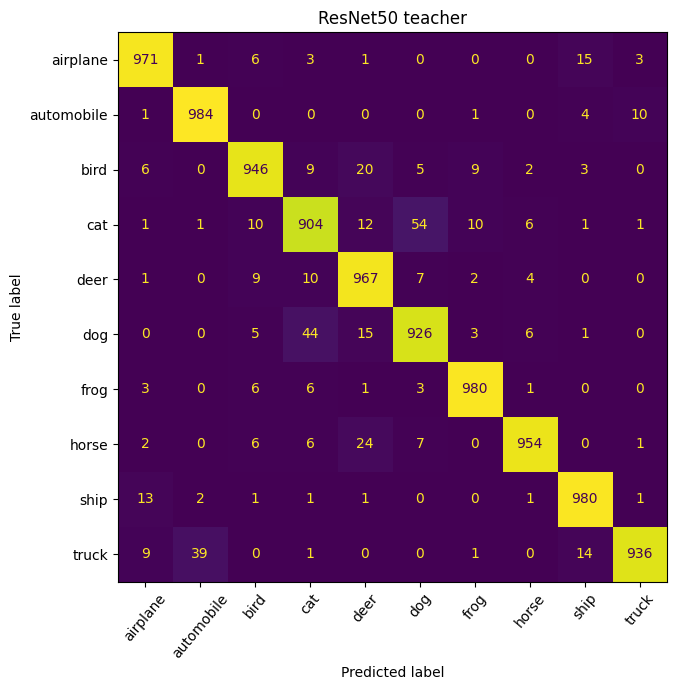

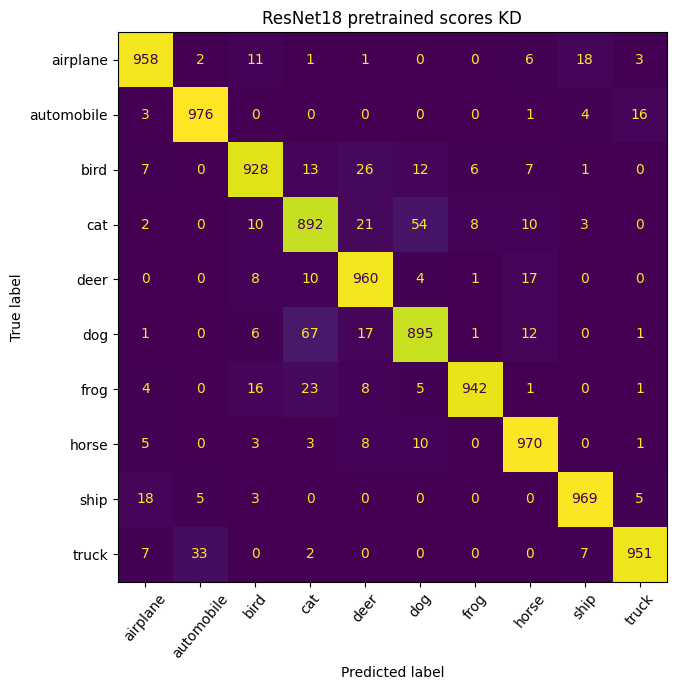

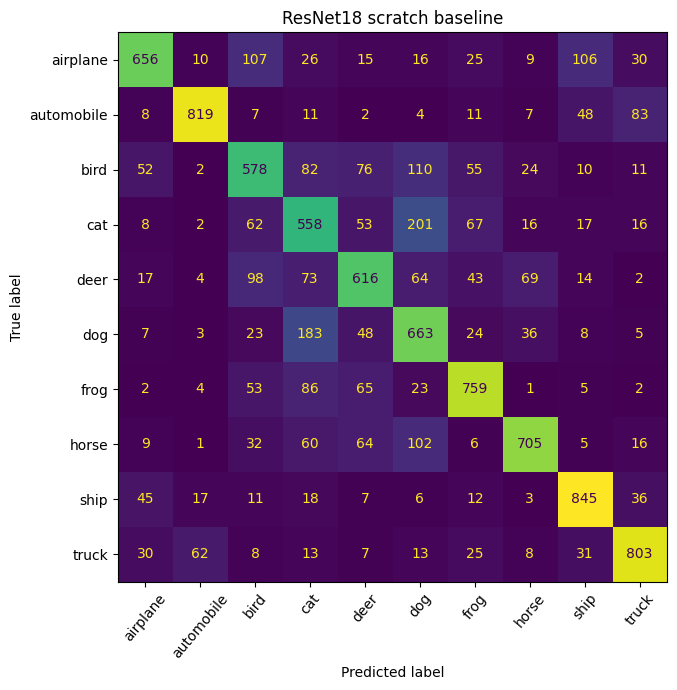

In [11]:
def predict_all(net):
    net.eval();actual=[];pred=[]
    with torch.inference_mode():
        for x,y in test_loader:
            logits=net(x.to(device,non_blocking=True))
            pred.extend(logits.argmax(1).cpu().tolist())
            actual.extend(y.tolist())
    return np.asarray(actual),np.asarray(pred)

def load_named_model(name):
    if name.startswith('Custom'):
        if name=='Custom teacher w64':net=SmallCNN(64)
        else:
            factor=int(name.split('x')[1][0]);net=SmallCNN(64//factor)
    else:
        net=make_resnet('resnet50' if name.startswith('ResNet50') else 'resnet18',False)
    net.load_state_dict(torch.load(CKPT/(key_for(name)+'_best.pt'),map_location='cpu',weights_only=True))
    return net.to(device)

if RUN_CONFUSIONS:
    candidates=[x for x in comparison['Model'] if x.startswith('ResNet18 pretrained')]
    chosen=comparison.set_index('Model').loc[candidates,'Best val accuracy (%)'].idxmax()
    targets=['ResNet50 teacher',chosen,'ResNet18 scratch baseline']
    print('Modèle choisi par validation :',chosen)
    for name in targets:
        net=load_named_model(name)
        yt,yp=predict_all(net)
        cm=confusion_matrix(yt,yp,labels=list(range(10)))
        pd.DataFrame(cm,index=CLASSES,columns=CLASSES).to_csv(OUT/(key_for(name)+'_confusion.csv'))
        pd.DataFrame(classification_report(yt,yp,target_names=CLASSES,output_dict=True)).T.to_csv(OUT/(key_for(name)+'_classification_report.csv'))
        fig,ax=plt.subplots(figsize=(8,7))
        ConfusionMatrixDisplay(cm,display_labels=CLASSES).plot(ax=ax,xticks_rotation=50,colorbar=False,values_format='d')
        ax.set_title(name)
        save_show('confusion_'+key_for(name)+'.png')
        del net
        gc.collect();torch.cuda.empty_cache()